# Sliding-window and expected-time scheduling on CPIT

**Question:** Does a sliding-window look-ahead improve the Expected schedule on the same instance and against the same bound?

**Level**: 3

**Prerequisites**: 01-problem-and-published-data; 02-bound-and-feasible-plan

**Reading time**: 35 minutes

## Objectives

Run the literature-backed sliding-window heuristic, compare it with Expected on one shared instance, and explain its candidate-set, optimistic-tail, and deterministic-budget adaptations. The answer separates measured evidence from claims about other cases.

## Setup

From the repository root, install the pinned environment with these versions. The cell reports the versions actually imported.

```bash
pip install oreblocks==0.6.6 numpy==2.5.1 scipy==1.18.1 matplotlib==3.11.2
```

In [1]:
# Import the API and verify versions.
import importlib.metadata as metadata
import json
from pathlib import Path
import sys
import matplotlib.pyplot as plt
sys.path.insert(0,str(Path('../../../data-pipeline').resolve()))
from pipeline.io.schema import Case,DepositSpec,Scenario
from pipeline.model.instances import build_instance
import oreblocks as ob
for package in ('oreblocks','numpy','scipy','matplotlib'):
    print(package,metadata.version(package))

oreblocks 0.6.6
numpy 2.5.1
scipy 1.18.1
matplotlib 3.11.2


## Data

PhaseFlow maintains the deterministic generator and instance builder; its code is MIT-licensed. The case declares a vein, seed 31, dimensions 4×4×3, four periods, and capacities; it is not field data. twin-porphyry-s is a separate derived manifest. Newman1 is a MineLib aggregate; its block files have academic-download terms and are not redistributed.

Per-file provenance: the committed aggregates are data/derived/manifests/newman1-published.json and data/derived/manifests/twin-porphyry-s.json. MineLib publishes its record at https://minelib.org/v1/Results.xhtml; MineLib owns the benchmark, and its source files carry academic-download terms. PhaseFlow owns the synthetic generator at https://github.com/fsantibanezleal/CAOS_PhaseFlow under the MIT license; its implementation is data-pipeline/pipeline/model/instances.py. The seed and scenario for this example are explicit in code.

In [2]:
# Build the instance through the pipeline and read committed aggregates.
case = Case(
    id='nb-vein-4x4x3',
    category='teaching',
    title_en='Small vein twin',
    title_es='Gemelo pequeño de veta',
    deposit=DepositSpec(kind='twin', archetype='vein', dims=(4, 4, 3), seed=31),
    scenario=Scenario(
        periods=4, discount_rate=0.08,
        capacity_fraction=(0.70, 0.50),
        resource_names=('mining', 'processing'),
    ),
)
instance=build_instance(case)
newman=json.loads(Path('../../../data/derived/manifests/newman1-published.json').read_text(encoding='utf-8'))
twin=json.loads(Path('../../../data/derived/manifests/twin-porphyry-s.json').read_text(encoding='utf-8'))
print('contract accepted:',instance.report.ok,'| blocks:',instance.n_blocks)
print('committed cases:',newman.get('case_id',newman.get('case')),twin.get('case_id',twin.get('case')))

contract accepted: True | blocks: 48
committed cases: newman1-published twin-porphyry-s


## Method

The cumulative model assigns discounted value to window and tail slots: maximize the sum of p_i(δ_j−δ_(j+1))y_ij, with monotonicity y_i,j ≤ y_i,j+1, precedence y_i,j ≤ y_a,j, and capacity constraints on increments. Cullenbine et al. (2011), https://doi.org/10.1007/s11590-011-0306-2, present the sliding-window approach for pit sequencing. The product dossier docs/methodologies/05_sliding-window.md documents the OreBlocks adaptation and its limits.

Cullenbine, Wood and Newman present the sliding time-window heuristic for open-pit sequencing as a look-ahead: solve a short horizon jointly, fix the first period, then advance. The rationale is temporal coupling. A block that is only attractive because it unlocks a later block can be visible to the optimization inside the shared window, unlike a purely myopic ranking. The published article is the methodological source; this notebook runs the pinned OreBlocks implementation, not the authors' original code or benchmark.

The product's method dossier explains the implementation's material adaptation. A full industrial window model can be too large without a commercial solver, so OreBlocks constructs an LP-guided closed candidate prefix sized to the window capacity. Precedence closure matters: candidates should not omit prerequisites of selected blocks. The package still completes closure explicitly. The candidate policy is a product implementation detail and means this experiment should not be described as a bit-for-bit replication of the paper.

Within a window, cumulative variables preserve monotonic extraction. A block's cumulative selection cannot decrease across slots; each selected block requires its predecessors in the same slot; resource rows constrain period increments. The unmodeled horizon is represented by an aggregated tail. Its capacity summarizes remaining capacity and its discount factor is optimistic, so the tail can overvalue later extraction. This is a known relaxation feature, not a forecast of realized cash flow.

Expected-weight TopoSort is the baseline because it uses the same precedence and capacity data and is the package's directly comparable time-order heuristic. We run both methods on one PhaseFlow-built vein case with the same four periods, economics and resource limits. The small instance lets us expose the method mechanics and inspect returned assignments. It does not measure the product's full-size performance or reproduce a published mine case.

Step 1. Recompute the resource certificate on the shared case.

In [3]:
# Compute the tightest per-resource critical-multiplier bound.
relaxations = [
    ob.cpit_lp_relaxation(
        instance.cpit, instance.precedence, resource=resource
    )
    for resource in range(instance.cpit.coef.shape[0])
]
bound = min(result.bound for result in relaxations)
print('shared upper bound:', round(bound, 2))

shared upper bound: 284685.82


Step 2. Run Expected as the comparator with data and capacities held fixed.

In [4]:
# Run the practical Expected baseline through OreBlocks.
expected, _ = ob.solve_cpit(
    instance.cpit, instance.precedence,
    method='expected', local_search=False,
)
print('Expected NPV:', round(expected.npv, 2))

Expected NPV: 179191.57


## Comparison

Cullenbine, Wood and Newman (2011), https://doi.org/10.1007/s11590-011-0306-2, propose jointly solving a window, fixing its first period, and sliding forward. This exposes near-horizon effects of early decisions, but the paper does not promise universal superiority. The package implementation uses relaxation-guided candidates and an optimistic tail; this result belongs to that implementation and these settings, not the paper's solver or original data. PhaseFlow's dossier records both wins and losses across its baked matrix.

The experimental table uses one upper certificate for both candidates. Each row includes NPV, mined blocks, gap and a bound-direction control. A gap is distance to this upper certificate, not a proof of suboptimality relative to the unknown integer optimum. The method with the larger NPV is better on this particular run under these constraints. A different deposit, tail configuration, candidate prefix, or solver budget could change that ordering.

Two figures expose different dimensions of the result. The objective comparison shows feasible value against the common ceiling. The load profile reveals which periods and resources drive the plan. Neither figure encodes all precedence arcs; use the package validator to check the returned schedule. The plot's capacity lines are limits, not measured operating throughput, and a near-binding line is not a production recommendation.

The source literature establishes the sliding-window family and its role in open-pit planning; the product dossier records the tested version, candidate rule, runtime tradeoffs and cases where it loses. This notebook uses that dossier to avoid a simplistic claim that look-ahead always wins. In the baked matrix, sliding window improves many cases but loses on some. The small teaching run is consistent evidence for its mechanism, not an independent replication of those measured product results.

Step 3. Run the window with a reproducible node limit, bounding search without relying on machine clock time.

In [5]:
# Run the sliding-window MILP with a fixed node budget for reproducibility.
window = ob.sliding_window_schedule(
    instance.cpit, instance.precedence,
    window=2, fix=1, node_limit=50, mip_gap=0.01,
    relaxation=relaxations[0],
)
print('sliding-window NPV:', round(window.npv, 2))
print('mined blocks:', window.mined_blocks)

sliding-window NPV: 237344.67
mined blocks: 4


Validate both schedules with the same independent controls.

In [6]:
# First check the baseline schedule with independent controls.
expected_controls = ob.run_controls(
    instance.cpit, instance.precedence, expected
)
print('Expected controls:', expected_controls.__dict__)

Expected controls: {'duality_set_matches': True, 'duality_bound_error': 0.0, 'bound_geq_feasible': True, 'order_invariant': True, 'order_invariance_error': 0.0}


Now validate the window schedule separately with the same controls; this output is specific to that candidate and does not inherit Expected's result.

In [7]:
# Check the window plan's bound direction and order invariance.
window_controls = ob.run_controls(instance.cpit, instance.precedence, window)
print('controles de ventana:', window_controls.__dict__)

controles de ventana: {'duality_set_matches': True, 'duality_bound_error': 0.0, 'bound_geq_feasible': True, 'order_invariant': True, 'order_invariance_error': 0.0}


The left figure places each schedule NPV below the shared upper bound; it does not turn a heuristic into an optimum.

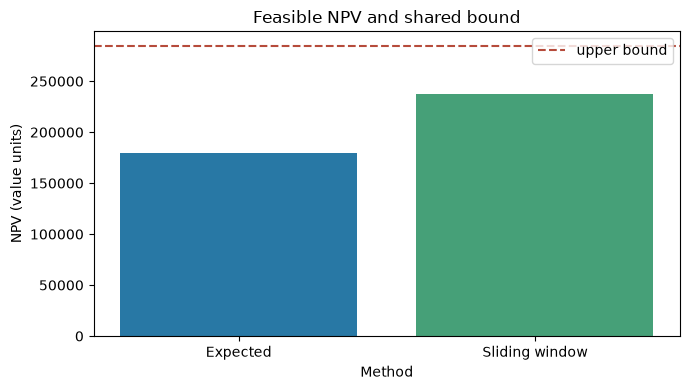

In [8]:
# Plot feasible values and the shared upper bound.
labels = ['Expected', 'Sliding window']
values = [expected.npv, window.npv]
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(labels, values, color=['#2878a5', '#46a078'])
ax.axhline(bound, color='#b64b3b', linestyle='--', label='upper bound')
ax.set(title='Feasible NPV and shared bound', xlabel='Method', ylabel='NPV (value units)')
ax.legend()
fig.tight_layout()
plt.show()

Reproducibility requires stating the solver and stopping budget. We use OreBlocks' deterministic node limit rather than a wall-clock cutoff, because elapsed-time stops can produce machine-dependent schedules. The time-window length and fixed prefix are explicit. Repeat the experiment only after holding these values constant; changing them answers a different question. Runtime from this compact instance is excluded from claims about production cases.

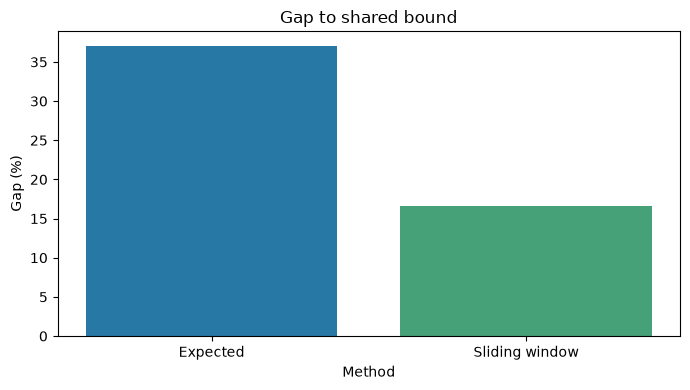

In [9]:
# Plot distance from the same upper bound.
gaps = [100 * (bound - value) / bound for value in values]
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(labels, gaps, color=['#2878a5', '#46a078'])
ax.set(title='Gap to shared bound', xlabel='Method', ylabel='Gap (%)')
fig.tight_layout()
plt.show()

Read the outcome in layers: contract acceptance tells us the instance was constructed consistently; the package result gives a feasible candidate; independent controls check bound direction and order invariance; the relaxation supplies the upper certificate; and the comparison isolates one heuristic choice. None of those layers validates the scenario against a mine plan. For that claim, use the published case dossier and its committed trace, whose provenance is kept separate from the generated teaching case.

## Results

**Answer:** Expected returned NPV 179191.57 with a 37.056% gap; sliding window returned 237344.67 with a 16.629% gap against the same 284685.82 bound. The difference was measured under a node limit on a small synthetic instance. It does not prove optimality or generalize to other deposits.

In [10]:
# Answer with the computed comparison.
print('Expected', round(expected.npv, 2), 'gap %', round(100*(bound-expected.npv)/bound, 3))
print('Sliding window', round(window.npv, 2), 'gap %', round(100*(bound-window.npv)/bound, 3))

Expected 179191.57 gap % 37.056
Sliding window 237344.67 gap % 16.629


## Summary

Read the outcome in layers: contract acceptance tells us the instance was constructed consistently; the package result gives a feasible candidate; independent controls check bound direction and order invariance; the relaxation supplies the upper certificate; and the comparison isolates one heuristic choice. None of those layers validates the scenario against a mine plan. For that claim, use the published case dossier and its committed trace, whose provenance is kept separate from the generated teaching case.

## References

- Cullenbine, Wood and Newman (2011), sliding-window heuristic: https://doi.org/10.1007/s11590-011-0306-2
- Chicoisne et al. (2012), CPIT relaxation: https://doi.org/10.1287/opre.1120.1050
- Rivera Letelier et al. (2020), scheduling methods: https://doi.org/10.1287/opre.2019.1965
- MineLib Newman1: https://minelib.org/v1/Results.xhtml
- Product dossier: docs/methodologies/05_sliding-window.md
- PhaseFlow source repository and synthetic-twin generator: https://github.com/fsantibanezleal/CAOS_PhaseFlow